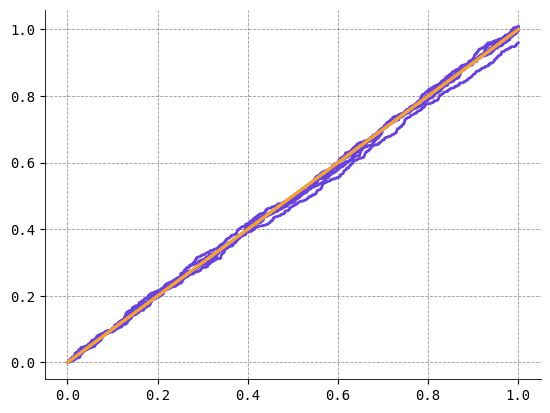

In [1]:
import matplotlib.pyplot as plt
import sigalg as sa

sa.style.set_style()

T = sa.Time.continuous(start=0, stop=1, dt=0.001)
W = sa.BrownianMotion.generate(n_trajectories=5, index=T, name="W")
t = sa.StochasticProcess.from_time(process=W)

_, ax = plt.subplots()
W.quad_var().plot_trajectories(ax, colors=[sa.style.purple])
t.plot_trajectories(ax, colors=[sa.style.amber])
plt.show()

In [2]:
import numpy as np
import sigalg as sa

T = sa.Time.continuous(start=0, stop=4, dt=0.001)
W = sa.BrownianMotion.generate(
    n_trajectories=5,
    index=T,
    name="W",
    random_state=42,
)

ito_integral = sa.ProcessTransforms.ito_integral
quad_var = sa.ProcessTransforms.quad_var


def f(X: sa.StochasticProcess) -> sa.StochasticProcess:
    return X**2


def f_prime(X: sa.StochasticProcess) -> sa.StochasticProcess:
    return 2 * X


increment = ito_integral(integrator=f(W))
classical_term = ito_integral(f_prime(W), W)
ito_correction = ito_integral(integrator=quad_var(W))


np.allclose(increment, classical_term + ito_correction)


True

In [3]:
import sigalg as sa

S_0, r, u, d, T = 100, 0.05, 1.1, 0.9, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    risk_free_rate=r,
    length=T,
    mode="enum",
)

K = 100
euro_call = sa.Claim.european_option(model=S, strike=K, type="call", name="euro_call")

Delta, B, V = S.replicating_portfolio(claim=euro_call)
X = euro_call.price_process()

X.last_rv == V.last_rv
all(np.allclose(V[t + 1], (1 + r) * B[t] + S[t + 1] * Delta[t]) for t in range(T))

Q = S.emm()
X.discount(r).is_martingale(prob_measure=Q)

True

In [4]:
from math import prod

import numpy as np
import sigalg as sa

K = [[0.4, 0.6], [0.7, 0.3]]
pi = [0.2, 0.8]
T = 10

X = sa.MarkovChain.generate(kernel=K, initial_distribution=pi, length=T, mode="enum")

P = X.measure
np.allclose(
    P >> X, (P >> X[0]) * prod(P.conditional(X[t]) >> X[t + 1] for t in range(T))
)

True

In [5]:
import numpy as np
import sigalg as sa

S_0, u, m, d, r, T = 100, 1.1, 1.0, 0.9, 0.05, 4

S = sa.TrinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    middle_factor=m,
    down_factor=d,
    risk_free_rate=r,
    mode="enum",
    length=T,
)


K = 90
american_put = sa.Claim.american_option(
    strike=K,
    model=S,
    type="put",
    name="american_put",
)

theta = 0.5
Q = S.emm(theta=theta)
S.discount(r).is_martingale(prob_measure=Q)

X = american_put.price_process(theta=theta)
tau = american_put.exercise_time(theta=theta)
X.discount(r).is_martingale(prob_measure=Q, kind="super")

price = X[0]
discounted_expectation = american_put.discount(r).at(tau).expectation(measure=Q)

np.allclose(price, discounted_expectation)

True

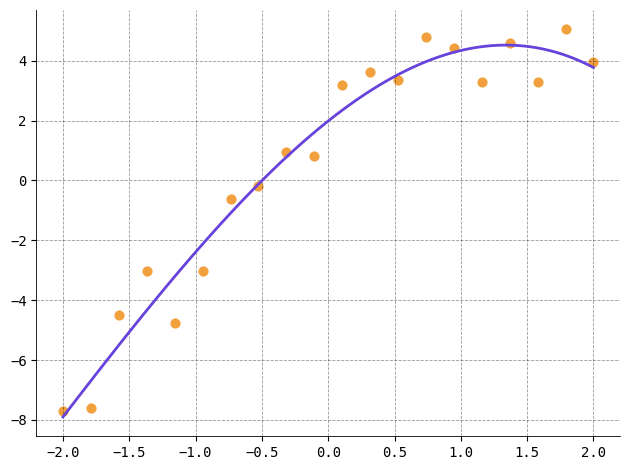

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import sigalg as sa

sa.style.set_style()

n = 20
Omega = sa.SampleSpace.from_sequence(size=20)
P = sa.ProbabilityMeasure.uniform(Omega, name="P")
H = sa.L2(Omega, measure=P)

X = sa.RandomVariable(domain=Omega, measure=P, mapping=np.linspace(-2, 2, n))
epsilon = sa.RandomVariable.from_rand(
    domain=Omega,
    measure=P,
    distribution="normal",
    name="epsilon",
    random_state=42,
)
Y = (2 + 3 * X - X**2 + epsilon).with_name("Y")

one = sa.RandomVariable.from_constant(domain=Omega, measure=P, constant=1, name="one")
polynomial_basis = [one, X, X**2, X**3]

Y_fit, coeffs_poly, dim_poly = H.proj(Y, polynomial_basis)

x_smooth = np.linspace(-2, 2, 100)
y_smooth = (
    coeffs_poly[0]
    + coeffs_poly[1] * x_smooth
    + coeffs_poly[2] * x_smooth**2
    + coeffs_poly[3] * x_smooth**3
)

_, ax = plt.subplots()
ax.scatter(X, Y, color=sa.style.amber, s=50)
ax.plot(x_smooth, y_smooth)
plt.tight_layout()
plt.show()